How likely is it to draw at least one heart and at least one face card in a five-card hand?

Let **A** be the event that the hand contains at least one heart, and **B** the event that it contains at least one face card (Jack, Queen, or King). The question asks for **A and B** (the joint event, or intersection): at least one heart **and** at least one face card. It is not asking for the union (A or B) or a conditional probability (A given B).

**Mutually exclusive?** No. A and B can happen together; for example, a hand with the Queen of hearts contains both a heart and a face card.

**Independent?** No. The events overlap in the three heart face cards, and knowing that B occurred changes the probability of A. For example, P(A) = 1 − C(39,5)/C(52,5) ≈ 0.341, while P(A | B) ≈ 0.474.


### Simulation type

I will simulate drawing a five-card hand from a standard 52-card deck, without replacement, to estimate the chance of getting at least one heart and at least one face card.

1. **Random process:** Shuffle a standard deck and draw five cards without putting any back.
2. **One trial and outcomes:** One trial is one five-card hand. Each possible outcome is a distinct set of five cards from the deck.
3. **Events and compound event:** Let **A** be drawing at least one heart and **B** be drawing at least one face card (Jack, Queen, or King). The success event is **A and B**, also written A ∩ B: the hand meets both conditions. This is a joint probability question, not a union (A or B) or a conditional probability (A given B).
4. **Mutual exclusivity:** A and B are not mutually exclusive. For example, the Queen of hearts belongs to both categories, and a hand containing it satisfies both events.
5. **Independence:** A and B are not independent. P(A) ≈ 0.341, while P(A | B) ≈ 0.474, so knowing B occurred changes the probability of A.

### Response to Al

Let H be drawing a heart and K be drawing a king. **They are not mutually exclusive**, because the king of hearts belongs to both events, so P(H ∩ K) = 1/52 rather than 0. **They are independent**, because P(H ∩ K) = 1/52 = (13/52)(4/52) = P(H)P(K). Equivalently, knowing the card is a king leaves the probability it is a heart at 1/4, the same as P(H).

### Technical prompt for Al

I am using Python 3 in a Jupyter notebook with pandas and NumPy available. Represent a standard 52-card deck as a pandas DataFrame with rank and suit columns. Simulate repeated five-card hands drawn without replacement, using a reproducible random seed. For each hand, define event A as at least one heart and event B as at least one face card (Jack, Queen, or King), then report the estimated probability of A and B together. Provide concise, executable notebook code and explain how the Boolean event columns encode the joint event.

In [ ]:
import pandas as pd
import numpy as np

ranks = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "Jack", "Queen", "King", "Ace"]
suits = ["Hearts", "Diamonds", "Clubs", "Spades"]
deck = pd.DataFrame([(rank, suit) for suit in suits for rank in ranks], columns=["rank", "suit"])

n_hands = 100_000
rng = np.random.default_rng(seed=42)
hands = []
for hand_id in range(n_hands):
    cards = rng.choice(len(deck), size=5, replace=False)
    hand = deck.iloc[cards].copy()
    hand["hand_id"] = hand_id
    hands.append(hand)
draws = pd.concat(hands, ignore_index=True)

face_ranks = {"Jack", "Queen", "King"}
events = draws.groupby("hand_id").agg(
    A_heart=("suit", lambda x: (x == "Hearts").any()),
    B_face_card=("rank", lambda x: x.isin(face_ranks).any()),
).reset_index()
events["A_and_B"] = events["A_heart"] & events["B_face_card"]

estimated_probability = events["A_and_B"].mean()
print(f"Estimated P(A and B): {estimated_probability:.4f}")
events.head()

### Technical prompt for empirical probability

In my Python 3 Jupyter Notebook, I have simulated 100,000 five-card hands using pandas and NumPy. A DataFrame named `events` contains one row per hand and a Boolean column named `A_and_B`, which is True when that hand contains at least one heart and at least one face card. Write a short code cell to calculate the empirical probability as the number of successful trials divided by the total number of trials. Display the success count, trial count, and estimated probability.

In [2]:
# Empirical probability = successful simulated hands / total simulated hands
successes = int(events["A_and_B"].sum())
trials = len(events)
empirical_probability = successes / trials

print(f"Successful hands: {successes:,}")
print(f"Total simulated hands: {trials:,}")
print(f"Empirical probability of A and B: {empirical_probability:.4f} ({empirical_probability:.2%})")

Successful hands: 58,252
Total simulated hands: 100,000
Empirical probability of A and B: 0.5825 (58.25%)


### Answer to the question

For a five-card hand, the chance of getting **at least one heart and at least one face card** (Jack, Queen, or King) is about **58%**. In the 100,000-hand simulation, **58,252 of 100,000** hands met both conditions, so the empirical probability is **0.5825 (58.25%)**. The theoretical probability is **1,507,701 / 2,598,960 ≈ 0.5801 (58.01%)**. The exact count comes from inclusion-exclusion: count all five-card hands, subtract hands with no hearts and hands with no face cards, then add back hands with neither condition because they were subtracted twice.

The graph below compares the empirical probability from the simulation with the theoretical probability. The bars are close in height, showing that the observed fraction of successful hands is near the exact chance of 58.01%. This supports the conclusion that a randomly dealt five-card hand has about a 58% chance of containing both at least one heart and at least one face card; a small difference is expected from simulation variability.

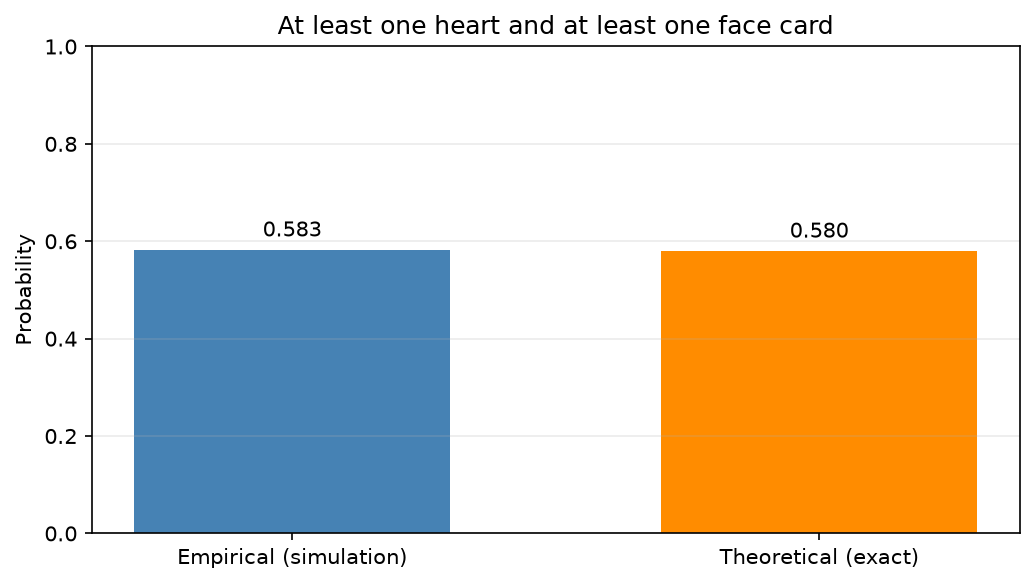

In [3]:
import matplotlib.pyplot as plt

theoretical_probability = 1507701 / 2598960
labels = ["Empirical (simulation)", "Theoretical (exact)"]
values = [empirical_probability, theoretical_probability]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, values, color=["steelblue", "darkorange"], width=0.6)
ax.set_ylim(0, 1)
ax.set_ylabel("Probability")
ax.set_title("At least one heart and at least one face card")
ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=4)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Graph interpretation:** The bars compare the simulated proportion of successful hands with the exact probability of about 0.580. Their heights should be close, supporting the answer that roughly 58% of five-card hands contain at least one heart and at least one face card. A small difference between bars is expected from simulation variability.